#### Import Library

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#### Load Data

In [2]:
data = pd.read_excel(r'D:\Daiict_Py\PY self study\swiggy data analysis\swiggy_data.xlsx')

In [3]:
data.head()

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,2025-04-17,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65
4,Karnataka,Bengaluru,2025-03-13,Srinidhi Sagar Deluxe,Kengeri,Recommended,Mix Raitha,130.0,4.0,0


#### Meta Data

In [4]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 197430 entries, 0 to 197429
Data columns (total 10 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   State            197430 non-null  object        
 1   City             197430 non-null  object        
 2   Order Date       197430 non-null  datetime64[ns]
 3   Restaurant Name  197430 non-null  object        
 4   Location         197430 non-null  object        
 5   Category         197430 non-null  object        
 6   Dish Name        197430 non-null  object        
 7   Price (INR)      197430 non-null  float64       
 8   Rating           197430 non-null  float64       
 9   Rating Count     197430 non-null  int64         
dtypes: datetime64[ns](1), float64(2), int64(1), object(6)
memory usage: 15.1+ MB


In [5]:
data.shape

(197430, 10)

In [6]:
data.isna().sum()

State              0
City               0
Order Date         0
Restaurant Name    0
Location           0
Category           0
Dish Name          0
Price (INR)        0
Rating             0
Rating Count       0
dtype: int64

In [7]:
data.duplicated().sum()

np.int64(27)

In [8]:
round(data.duplicated().sum()*100/data.shape[0],2)

np.float64(0.01)

In [9]:
data.drop_duplicates(inplace=True)

In [10]:
data.shape

(197403, 10)

In [11]:
data.describe(include='all')

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
count,197403,197403,197403,197403,197403,197403,197403,197403.000000,197403.000000,197403.000000
unique,28,28,NaN,993,977,4972,59064,NaN,NaN,NaN
top,Karnataka,Bengaluru,NaN,McDonald's,Gomti Nagar,Recommended,Choco Lava Cake,NaN,NaN,NaN
freq,20072,20072,NaN,13528,2091,24098,303,NaN,NaN,NaN
mean,NaN,NaN,2025-05-01 19:42:28.028145152,NaN,NaN,NaN,NaN,268.501413,4.341579,28.323637
min,NaN,NaN,2025-01-01 00:00:00,NaN,NaN,NaN,NaN,0.950000,1.500000,0.000000
25%,NaN,NaN,2025-03-01 00:00:00,NaN,NaN,NaN,NaN,139.000000,4.300000,0.000000
50%,NaN,NaN,2025-05-02 00:00:00,NaN,NaN,NaN,NaN,229.000000,4.400000,2.000000
75%,NaN,NaN,2025-07-01 00:00:00,NaN,NaN,NaN,NaN,329.000000,4.500000,15.000000
max,NaN,NaN,2025-08-31 00:00:00,NaN,NaN,NaN,NaN,8000.000000,5.000000,999.000000


#### KPI'S

In [12]:
data.head(3)

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48


1. Total Sales

In [13]:
total_sales = data['Price (INR)'].sum()
print(f'total sales: {round(total_sales,2)}')

total sales: 53002984.47


2. Average Rating

In [14]:
avg_rating = data['Rating'].mean()
print(f'average rating: {round(avg_rating,1)}')

average rating: 4.3


3. Average Order Value

In [15]:
aov = data['Price (INR)'].mean()
print(f'average order value: {round(aov,2)}')

average order value: 268.5


4. Rating Count

In [16]:
ratings_count = data['Rating Count'].sum()
print(f'rating count: {round(ratings_count,2)}')

rating count: 5591171


5. Total Orders

In [17]:
total_order = data['Order Date'].count()
print(f'total orders: {total_order}')

total orders: 197403


#### Charts 

In [18]:
data.head(2)

,State,City,Order Date,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25


1. Monthly Sales Trend

In [19]:
from datetime import datetime
data.insert(3, 'Month', data['Order Date'].dt.month)

In [20]:
data['Month'].head(3)

0    6
1    4
2    1
Name: Month, dtype: int32

In [21]:
data.insert(4,'Year_Month', data['Order Date'].dt.year.astype(str)+ '-' + data['Order Date'].dt.month.astype(str))

In [22]:
data['Year_Month'].head(3)

0    2025-6
1    2025-4
2    2025-1
Name: Year_Month, dtype: object

In [23]:
data1 = data.groupby('Year_Month')['Price (INR)'].sum().reset_index(name='Total Price')
data1

,Year_Month,Total Price
0,2025-1,6823981.33
1,2025-2,6268161.67
2,2025-3,6572738.20
3,2025-4,6590449.00
4,2025-5,6792621.35
5,2025-6,6513865.19
6,2025-7,6650268.51
7,2025-8,6790899.22


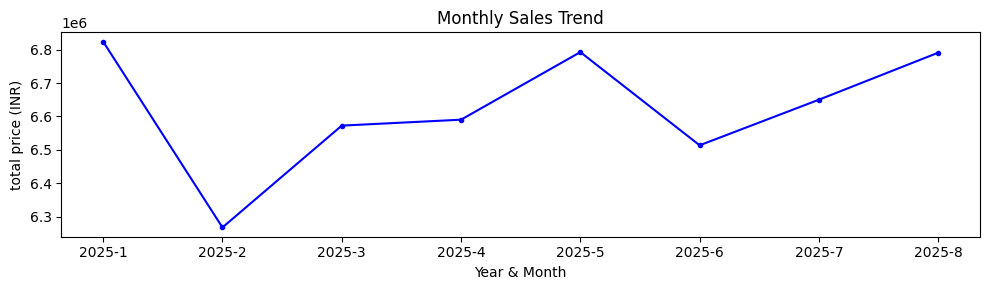

In [24]:
x = data1['Year_Month']
y = data1['Total Price']

plt.figure(figsize=(10,3))

plt.title('Monthly Sales Trend')
plt.plot(x,y,'b.-')
plt.xlabel('Year & Month')
plt.ylabel('total price (INR)')

plt.tight_layout()

plt.show()

In [25]:
data.head(2)

,State,City,Order Date,Month,Year_Month,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,6,2025-6,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,4,2025-4,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25


2. Daily Sales Trend: Highliting order and revenue variations across days of the week.

In [26]:
data.insert(5,'Day_Name',data['Order Date'].dt.day_name())
data.head(4)

,State,City,Order Date,Month,Year_Month,Day_Name,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count
0,Karnataka,Bengaluru,2025-06-29,6,2025-6,Sunday,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0
1,Karnataka,Bengaluru,2025-04-03,4,2025-4,Thursday,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25
2,Karnataka,Bengaluru,2025-01-15,1,2025-1,Wednesday,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48
3,Karnataka,Bengaluru,2025-04-17,4,2025-4,Thursday,Srinidhi Sagar Deluxe,Kengeri,Recommended,Kesari Bath,65.0,4.6,65


    Day_Name  Total Price
1     Monday   7444475.14
5    Tuesday   7358996.01
6  Wednesday   7541692.52
4   Thursday   7663248.59
0     Friday   7579482.84
2   Saturday   7778260.40
3     Sunday   7636828.97


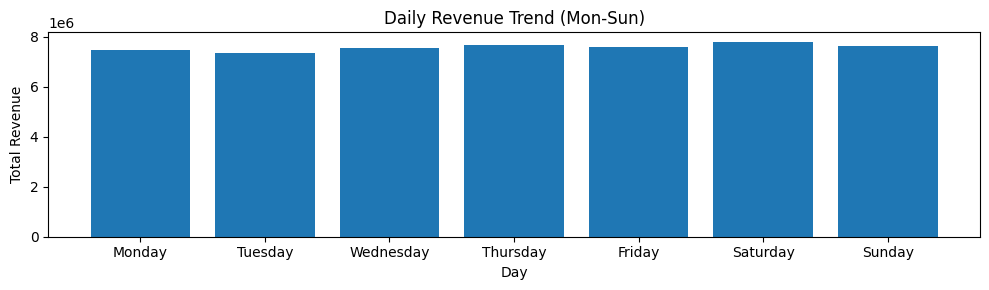

In [27]:
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday',
             'Friday', 'Saturday', 'Sunday']

data2 = data.groupby('Day_Name')['Price (INR)'].sum().reset_index(name='Total Price')

data2['Day_Name'] = pd.Categorical(
    data2['Day_Name'],
    categories=day_order,
    ordered=True
)

data2 = data2.sort_values('Day_Name', ascending= True)

print(data2)

x = data2['Day_Name']
y = data2['Total Price']

plt.figure(figsize=(10, 3))
plt.title('Daily Revenue Trend (Mon-Sun)')
plt.bar(x, y)
plt.xlabel('Day')
plt.ylabel('Total Revenue')

plt.tight_layout()
plt.show()

3. Total Sales By Food (Veg vs Non-Veg)

In [35]:
non_veg_keywords = ["chicken", "egg", "fish", "afghani", "mutton", "prawn",
                    "biryani", "kabab", "kebab", "non-veg", "non veg"]

pattern = '|'.join(non_veg_keywords)

data['Food_Category'] = np.where(
    data['Dish Name'].str.lower().str.contains(pattern, na=False),
    "Non-Veg", "Veg"
)

In [36]:
name = data['Dish Name'].str.lower()
is_non_veg = name.str.contains(pattern, na=False)
is_veg_labeled = name.str.contains(r'\b(?:veg|paneer|soya|mushroom)\b', na=False)

data['Food_Category'] = np.where(is_non_veg & ~is_veg_labeled, "Non-Veg", "Veg")

In [37]:
data.head(3)

,State,City,Order Date,Month,Year_Month,Day_Name,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count,Food_Category
0,Karnataka,Bengaluru,2025-06-29,6,2025-6,Sunday,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0,Veg
1,Karnataka,Bengaluru,2025-04-03,4,2025-4,Thursday,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25,Veg
2,Karnataka,Bengaluru,2025-01-15,1,2025-1,Wednesday,Srinidhi Sagar Deluxe,Kengeri,Recommended,Chow Chow Bath,117.0,4.7,48,Veg


In [43]:
food_revenue = data.groupby(['Food_Category'])['Price (INR)'].sum().reset_index(name='Total Revenue')
food_revenue

,Food_Category,Total Revenue
0,Non-Veg,17304243.63
1,Veg,35698740.84


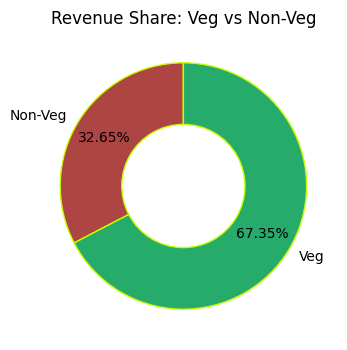

In [97]:
plt.figure(figsize=(4, 4))
plt.pie(
    food_revenue['Total Revenue'],
    labels=['Non-Veg', 'Veg'],
    autopct='%.2f%%',
    colors=['#AD4642','#26AB6A'],
    startangle=90,
    pctdistance=0.75,
    wedgeprops=dict(width=0.5, edgecolor='#C8FF00')
)
plt.title('Revenue Share: Veg vs Non-Veg')
plt.show()

4. Total Sales by State

In [98]:
data['State'].nunique()

28

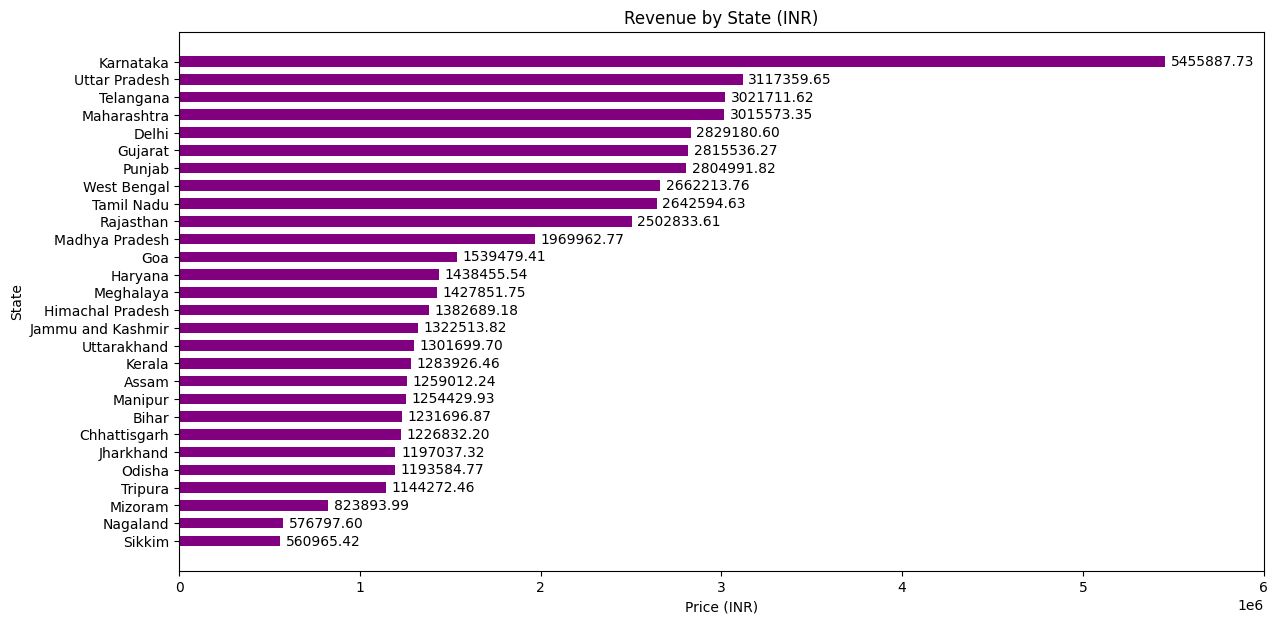

In [142]:
df = data.groupby('State')['Price (INR)'].sum().reset_index(name= 'Total_Revenue').sort_values("Total_Revenue")

plt.figure(figsize=(14, 7))
plt.title('Revenue by State (INR)')
bars = plt.barh(df['State'], df['Total_Revenue'], color='purple', height=0.6)
plt.bar_label(bars, fmt='%.2f', padding=4)   # shows the full value
plt.xlabel('Price (INR)')
plt.ylabel('State')
plt.margins(x=0.1)   # extra space so labels don't get cut off
plt.show()

5. Quarterly Performance Summary- Combines sales, rating and order by quarter.

In [147]:
data['Order Date'] = pd.to_datetime(data['Order Date'])
data['Quarter'] = data['Order Date'].dt.to_period("Q").astype(str)

data.head(2)


,State,City,Order Date,Month,Year_Month,Day_Name,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count,Food_Category,Quarter
0,Karnataka,Bengaluru,2025-06-29,6,2025-6,Sunday,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0,Veg,2025Q2
1,Karnataka,Bengaluru,2025-04-03,4,2025-4,Thursday,Srinidhi Sagar Deluxe,Kengeri,Recommended,Badam Milk,52.0,4.5,25,Veg,2025Q2


In [160]:
Quarterly_summary = data.groupby('Quarter').agg(
    Total_Sales = ('Price (INR)', 'sum'),
    Avg_Rating = ('Rating', 'mean'),
    Total_Orders = ('Order Date', 'count')
).sort_values('Quarter', ascending=True)

Quarterly_summary['Total_Sales'] = Quarterly_summary['Total_Sales'].round(0)
Quarterly_summary['Avg_Rating'] = Quarterly_summary['Avg_Rating'].round(2)

Quarterly_summary


,Total_Sales,Avg_Rating,Total_Orders
Quarter,,,
2025Q1,19664881.0,4.34,73085
2025Q2,19896936.0,4.34,74155
2025Q3,13441168.0,4.34,50163


6. Top 5 Cities by Sales

In [165]:
data.head(1)

,State,City,Order Date,Month,Year_Month,Day_Name,Restaurant Name,Location,Category,Dish Name,Price (INR),Rating,Rating Count,Food_Category,Quarter
0,Karnataka,Bengaluru,2025-06-29,6,2025-6,Sunday,Anand Sweets & Savouries,Rajarajeshwari Nagar,Snack,Butter Murukku-200gm,133.9,4.0,0,Veg,2025Q2


In [171]:
x = data.groupby('City')['Price (INR)'].sum().reset_index(name='Total Price').sort_values('Total Price', ascending= False)[0:5]
x

,City,Total Price
3,Bengaluru,5455887.73
18,Lucknow,3117359.65
11,Hyderabad,3021711.62
19,Mumbai,3015573.35
20,New Delhi,2829180.60


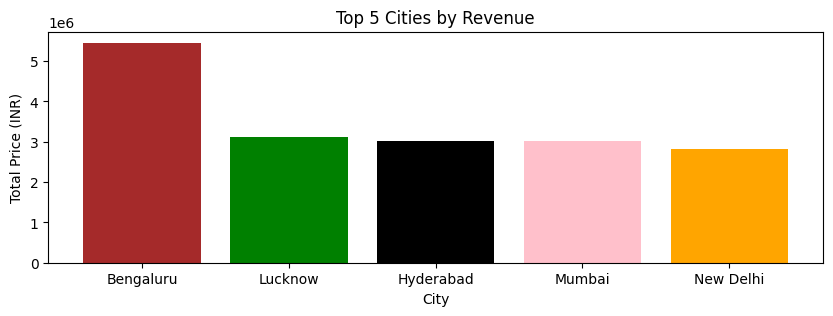

In [194]:
plt.figure(figsize=(10,3))
plt.title('Top 5 Cities by Revenue')
plt.bar(x['City'], x['Total Price'], color = ['brown','green','black','pink','orange'])
plt.xlabel('City')
plt.ylabel('Total Price (INR)')
plt.show()

# END